In [25]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import savgol_filter, medfilt
from scipy.optimize import curve_fit
import os

def analyze_and_plot_separate(num_measurements=20):
    results = []
    
    for i in range(1, num_measurements + 1):
        dmm_file = f'DMMdata_pt1000_{i}.csv'
        smu_file = f'SMUdata_pt1000_{i}.csv'
        
        # Sla over als bestanden niet bestaan in de map
        if not os.path.exists(dmm_file) or not os.path.exists(smu_file):
            print(f"Meting {i} bestanden niet gevonden. Slaat over.")
            continue
            
        # 1. Inladen & Kalibratie
        R_LN2, T_LN2 = 197, 77.0
        R_room, T_room = 1078.0, 294
        a = (T_room - T_LN2) / (R_room - R_LN2)
        b = T_LN2 - a * R_LN2

        dmm = pd.read_csv(dmm_file, skiprows=5, header=None, names=['R_pt1000'])
        dmm['T_K'] = a * dmm['R_pt1000'] + b

        with open(smu_file, 'r') as f:
            lines = f.readlines()
            data_start = next(j + 1 for j, line in enumerate(lines) if line.strip() == "")
        smu = pd.read_csv(smu_file, skiprows=data_start, header=None, sep='\t')
        
        # 2. Berekeningen maken
        V1, V2 = smu[0], smu[1]
        R_sample = (V1 - V2) / 0.2    # (0.1 - (-0.1))
        V_sample = (V1 - V2) / 2.0    # Werkelijke spanning over sample
        V_emf = (V1 + V2) / 2.0       # Thermo-elektrische spanning
        
        T, R, V_samp, V_e = dmm['T_K'].values, R_sample.values, V_sample.values, V_emf.values
        
        # Sorteren op T
        idx = np.argsort(T)
        T, R, V_samp, V_e = T[idx], R[idx], V_samp[idx], V_e[idx]
        
        # 3. Filtering & Pieken verwijderen
        valid = (R > -0.005) & (R < 0.02) & (T > 80) & (T < 125)
        T, R, V_samp, V_e = T[valid], R[valid], V_samp[valid], V_e[valid]
        
        if len(T) < 10: 
            continue
            
        R_med = medfilt(R, kernel_size=5)
        valid2 = np.abs(R - R_med) < 0.002
        T, R, V_samp, V_e = T[valid2], R[valid2], V_samp[valid2], V_e[valid2]
        
        T_uniq, indices = np.unique(T, return_index=True)
        R_uniq, V_samp_uniq, V_e_uniq = R[indices], V_samp[indices], V_e[indices]
        
        # 4. Savitzky-Golay
        window = min(41, len(R_uniq) - 1 if (len(R_uniq) - 1) % 2 != 0 else len(R_uniq) - 2)
        R_sg = savgol_filter(R_uniq, window_length=window, polyorder=3) if window > 3 else R_uniq
            
        # 5. Fitten (Sigmoid) voor exacte Tc locatie
        def sigmoid(x, Rmax, k, Tc, Rmin):
            return Rmax / (1.0 + np.exp(np.clip(-k*(x-Tc), -100, 100))) + Rmin
            
        try:
            popt, _ = curve_fit(sigmoid, T_uniq, R_sg, p0=[np.max(R_sg), 1.0, 105.0, 0.0], maxfev=10000)
            Tc_fit = popt[2]
        except:
            popt = [np.max(R_sg), 1.0, 105.0, 0.0]
            Tc_fit = np.nan
            
        # 6. Waarden halen op de locatie van Tc
        if not np.isnan(Tc_fit):
            idx_tc = np.argmin(np.abs(T_uniq - Tc_fit))
            R_at_Tc, Vsamp_at_Tc, Vemf_at_Tc = R_uniq[idx_tc], V_samp_uniq[idx_tc], V_e_uniq[idx_tc]
        else:
            R_at_Tc = Vsamp_at_Tc = Vemf_at_Tc = np.nan

        groep = "1-10 (Boven stikstof)" if i <= 10 else "11-20 (Ernaast)"
        results.append({
            'Meting': i,
            'Groep': groep,
            'Tc_fit (K)': round(Tc_fit, 2),
            'R sample @ Tc (Ohm)': round(R_at_Tc, 6),
            'V sample @ Tc (V)': round(Vsamp_at_Tc, 6),
            'V emf @ Tc (V)': round(Vemf_at_Tc, 6)
        })
        
        # --- LOSSE GRAFIEK GENEREREN EN OPSLAAN ---
        plt.figure(figsize=(8, 5))
        
        # Meting 1-10 in blauw, meting 11-20 in oranje
        color_dot = 'dodgerblue' if i <= 10 else 'orange'
        color_line = 'darkblue' if i <= 10 else 'darkred'
        
        # Plot de data
        plt.plot(T_uniq, R_uniq, 'o', color=color_dot, alpha=0.3, markersize=4, label='Gefilterde Data')
        plt.plot(T_uniq, R_sg, '-', color=color_line, linewidth=2, label='Savitzky-Golay Fit')
        
        # Markeer de gevonden Tc
        if not np.isnan(Tc_fit):
            # Interpoleer de exacte y-waarde van de Savitzky-Golay lijn bij Tc
            y_tc = np.interp(Tc_fit, T_uniq, R_sg)
            plt.plot(Tc_fit, y_tc, 'ko', markersize=8, label=f'Tc = {Tc_fit:.2f} K')
            
        plt.title(f'R-T Curve - Meting {i} ({groep})')
        plt.xlabel('Temperatuur (K)')
        plt.ylabel('Gecompenseerde Weerstand (Ohm)')
        plt.xlim(90, 125)
        plt.grid(True, linestyle='--', alpha=0.6)
        plt.legend()
        plt.tight_layout()
        
        # Sla op en sluit grafiek af om geheugen te sparen
        plt.savefig(f'Meting_{i}_plot.png', dpi=150)
        plt.close() 

    # --- RESULTATEN TABEL ---
    df = pd.DataFrame(results)
    df.to_csv('Tc_results_table.csv', index=False)
    print("\nTabel succesvol opgeslagen als 'Tc_results_table.csv'.")
    print(df.to_string(index=False))

# Start the magic (checkt alle 20 files):
analyze_and_plot_separate(num_measurements=20)


Tabel succesvol opgeslagen als 'Tc_results_table.csv'.
 Meting                 Groep  Tc_fit (K)  R sample @ Tc (Ohm)  V sample @ Tc (V)  V emf @ Tc (V)
      1 1-10 (Boven stikstof)      103.88             0.005402           0.000540       -0.000083
      2 1-10 (Boven stikstof)      105.66             0.005739           0.000574       -0.000012
      3 1-10 (Boven stikstof)      106.15             0.005187           0.000519       -0.000023
      4 1-10 (Boven stikstof)      106.26             0.005016           0.000502       -0.000025
      5 1-10 (Boven stikstof)      106.26             0.005016           0.000502       -0.000025
      6 1-10 (Boven stikstof)      104.67             0.005445           0.000545       -0.000022
      7 1-10 (Boven stikstof)      103.60             0.005445           0.000544       -0.000024
      8 1-10 (Boven stikstof)      106.74             0.005208           0.000521       -0.000022
      9 1-10 (Boven stikstof)      110.40             0.005200

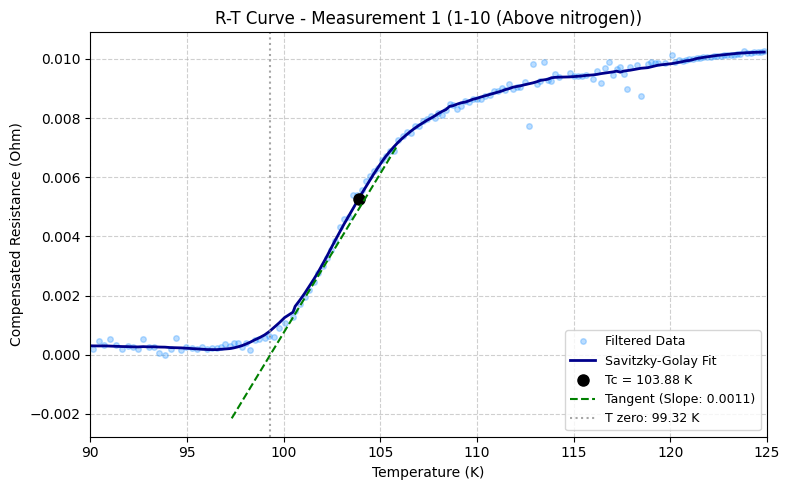

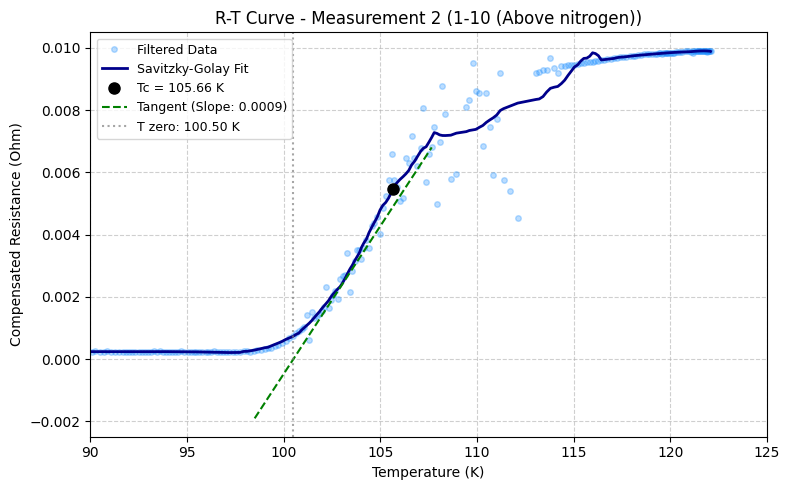

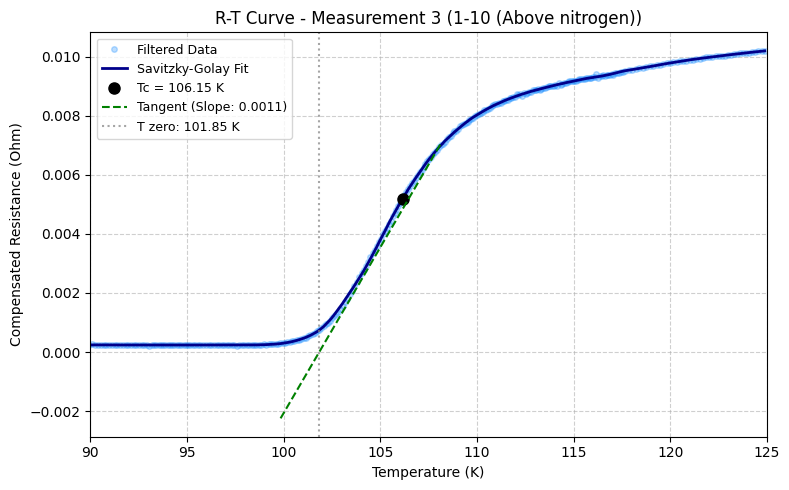

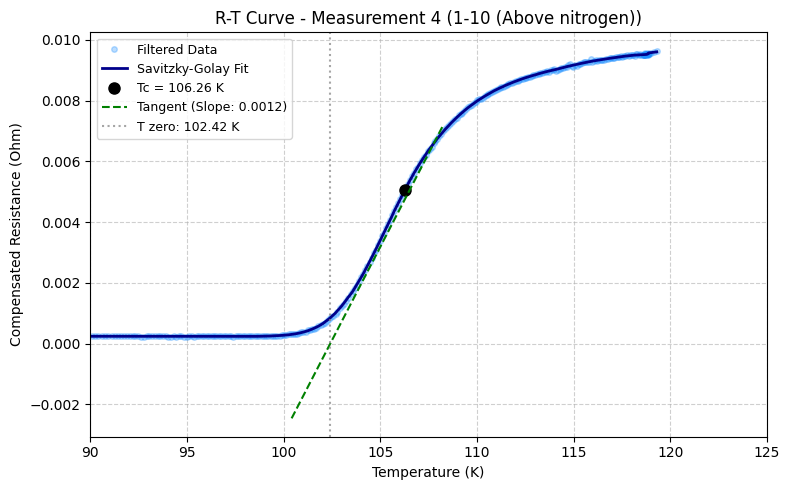

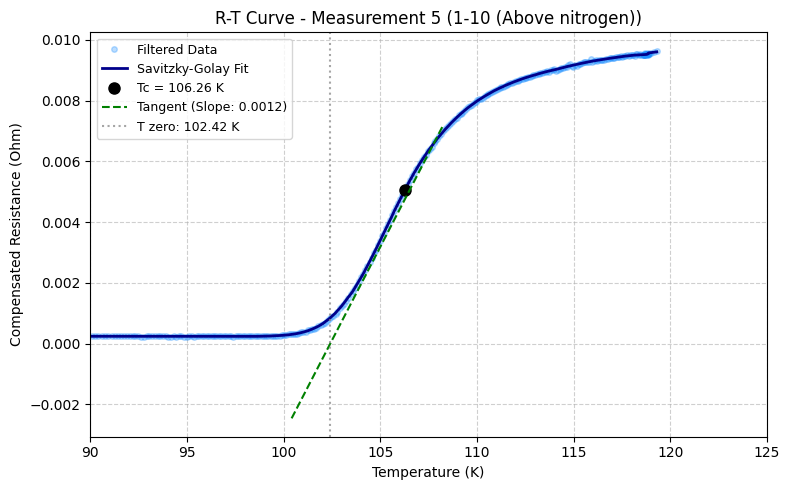

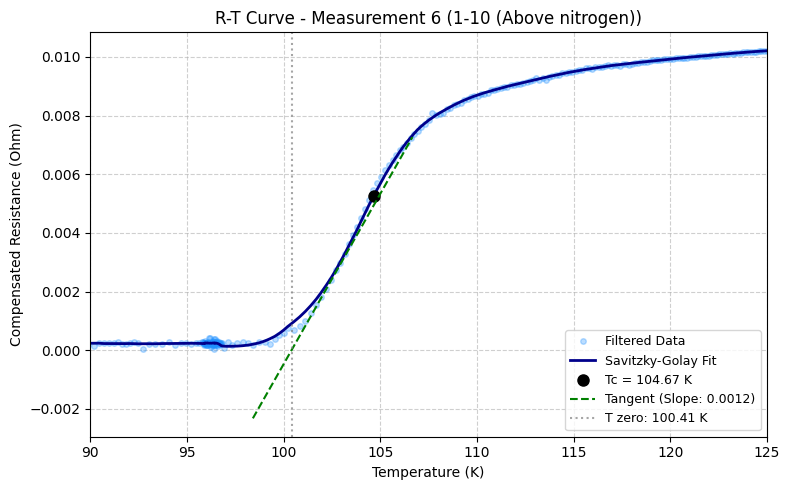

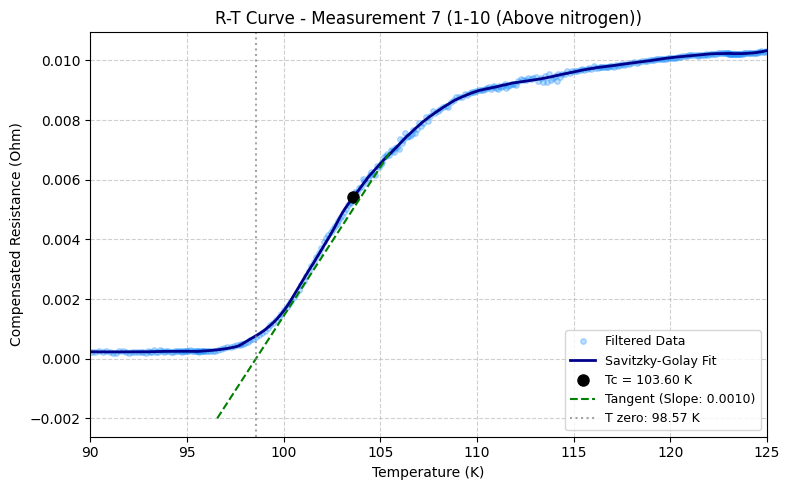

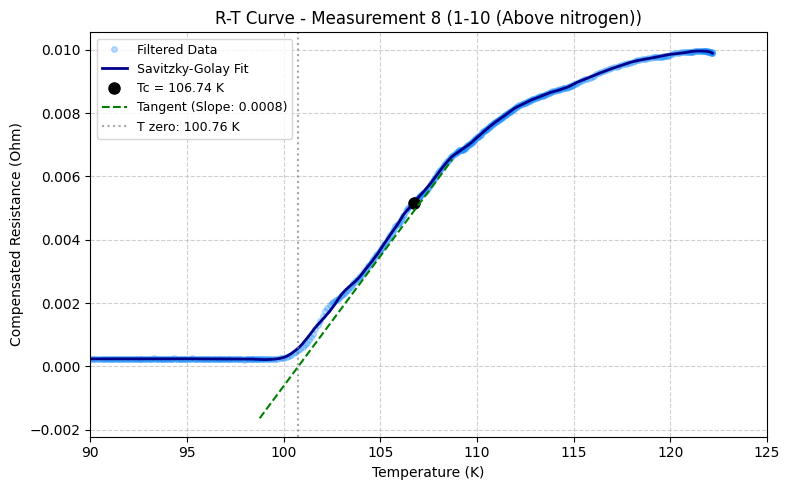

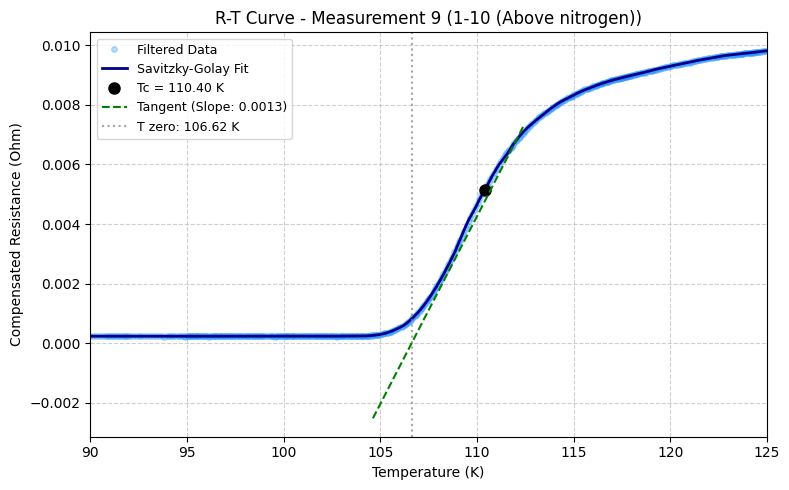

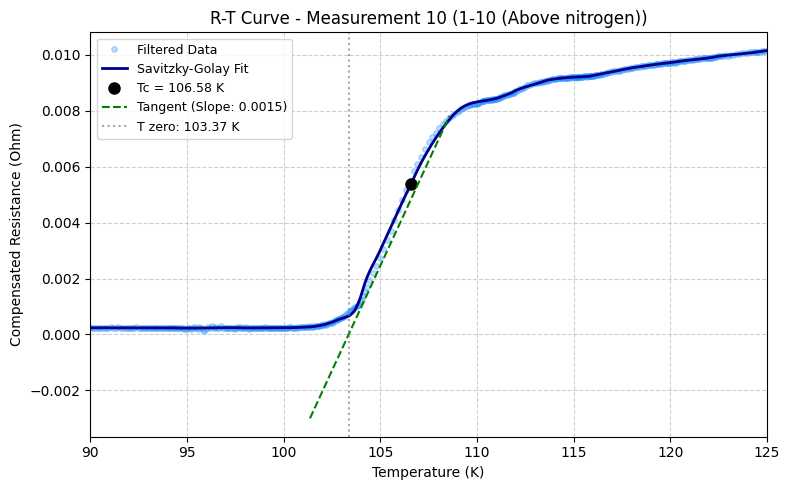

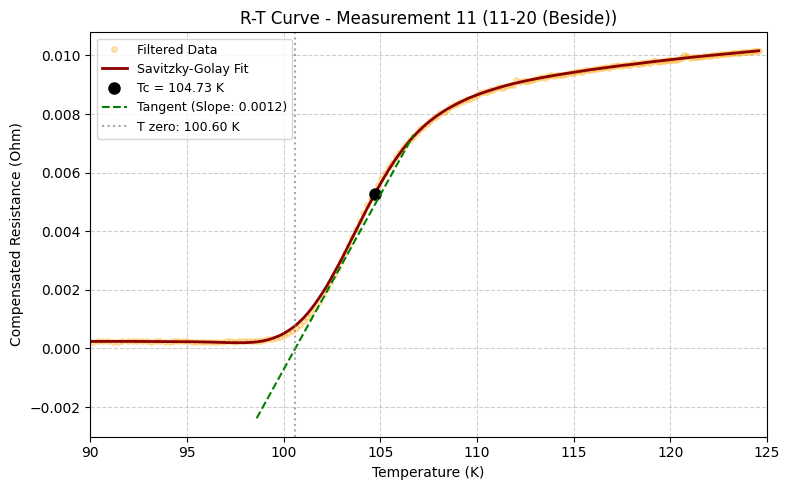

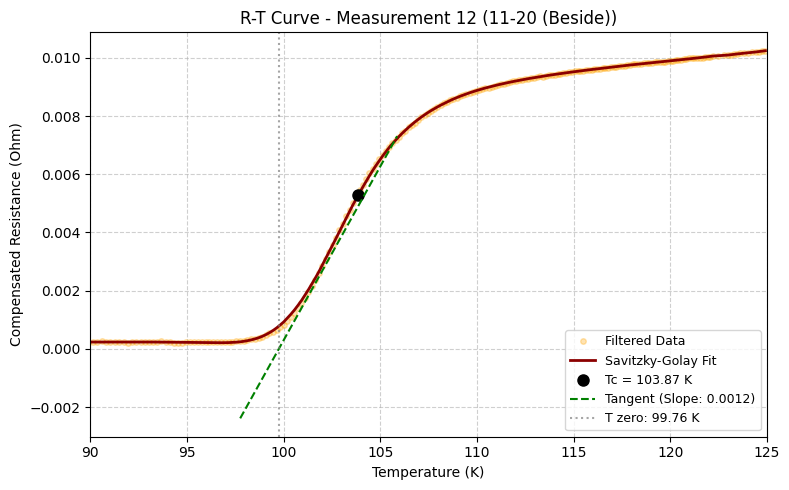

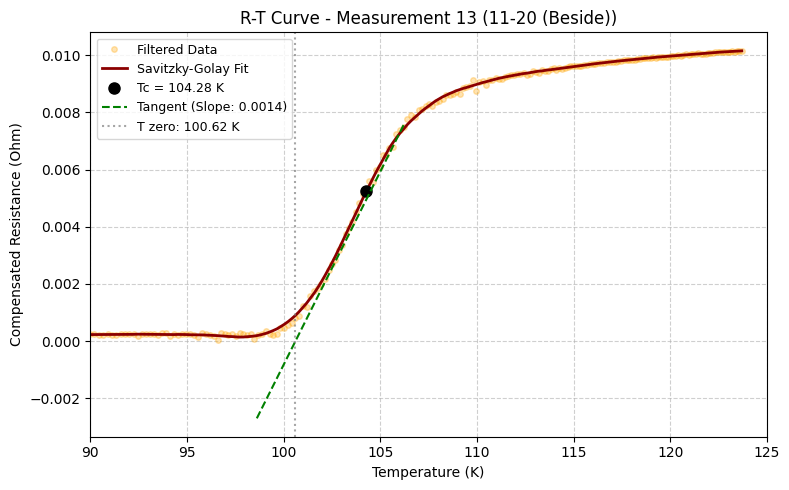

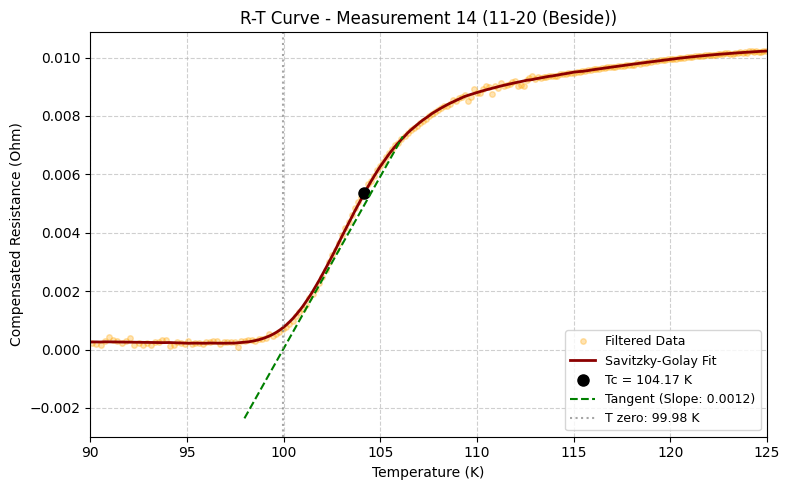

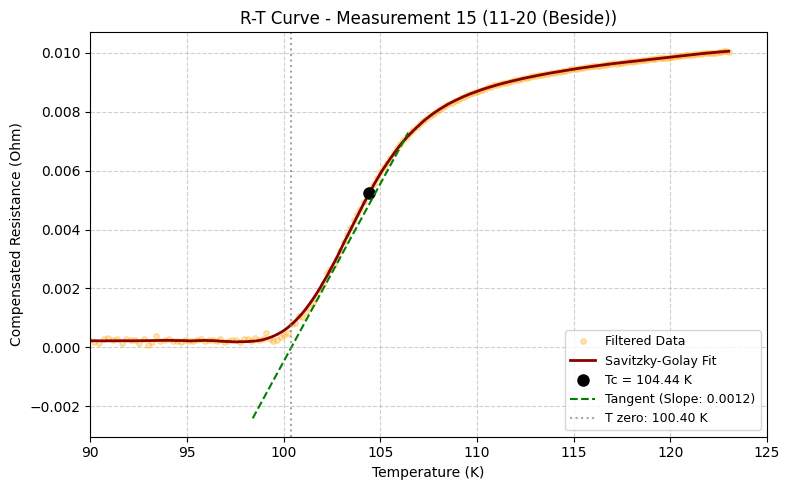

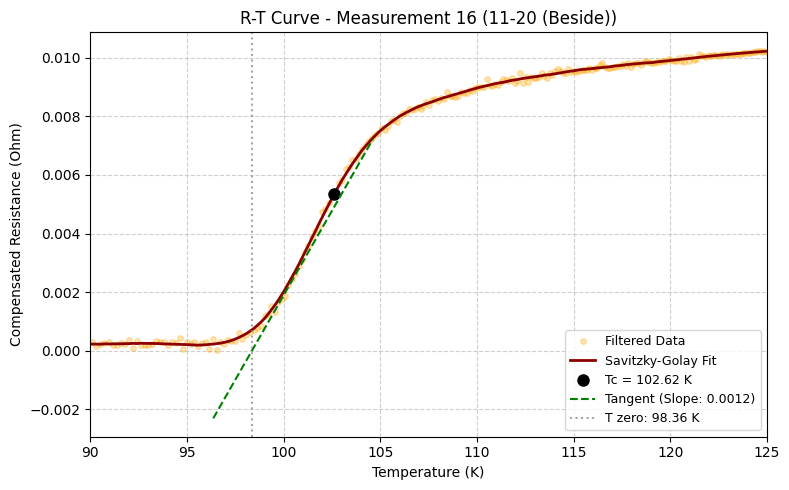

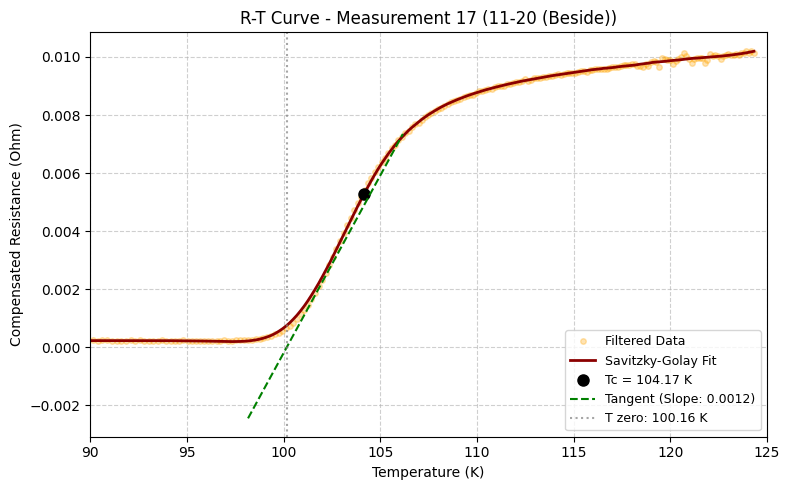

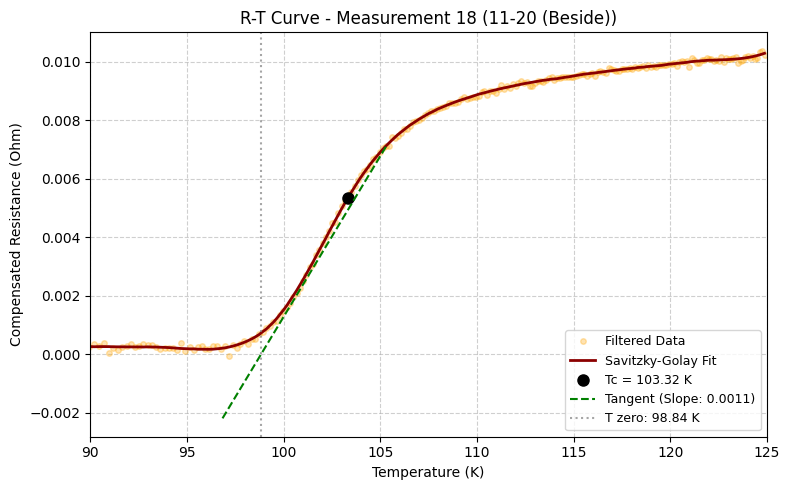

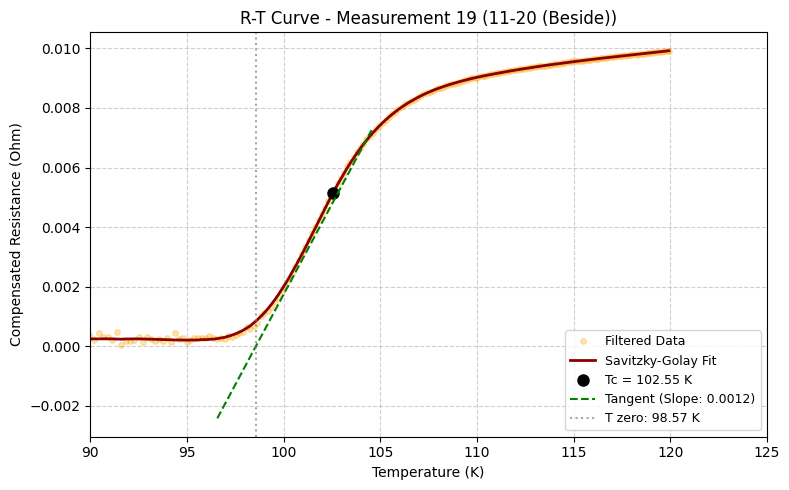

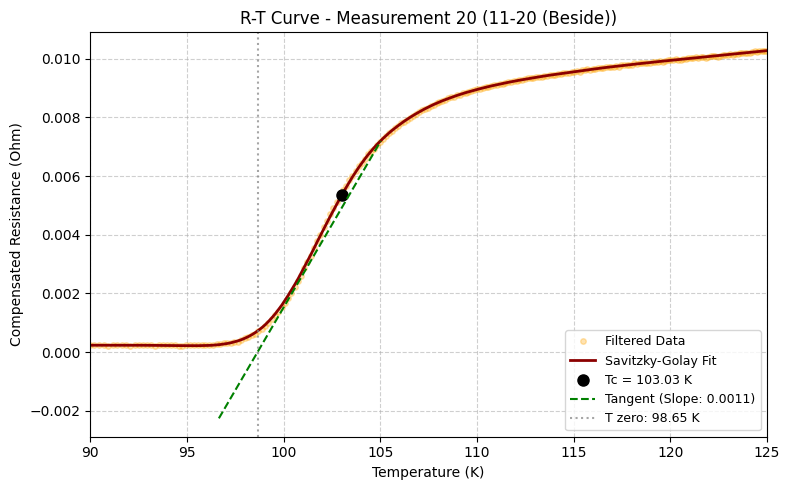


Table successfully saved as 'Tc_results_table.csv'.
 Measurement                 Group  Tc_fit (K)  Slope @ Tc (Ohm/K)  T zero intercept (K)  R sample @ Tc (Ohm)  V sample @ Tc (V)  V emf @ Tc (V)
           1 1-10 (Above nitrogen)      103.88            0.001077                 99.32             0.004912           0.000540       -0.000083
           2 1-10 (Above nitrogen)      105.66            0.000950                100.50             0.004900           0.000574       -0.000012
           3 1-10 (Above nitrogen)      106.15            0.001122                101.85             0.004833           0.000519       -0.000023
           4 1-10 (Above nitrogen)      106.26            0.001231                102.42             0.004731           0.000502       -0.000025
           5 1-10 (Above nitrogen)      106.26            0.001231                102.42             0.004731           0.000502       -0.000025
           6 1-10 (Above nitrogen)      104.67            0.001161           

In [28]:
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.optimize import curve_fit
from scipy.signal import medfilt, savgol_filter


def analyze_and_plot_separate(num_measurements=20):
  results = []

  for i in range(1, num_measurements + 1):
    dmm_file = f'DMMdata_pt1000_{i}.csv'
    smu_file = f'SMUdata_pt1000_{i}.csv'

    # Skip if files do not exist in the directory
    if not os.path.exists(dmm_file) or not os.path.exists(smu_file):
      print(f'Measurement {i} files not found. Skipping.')
      continue

    # 1. Loading & Calibration
    R_LN2, T_LN2 = 197, 77.0
    R_room, T_room = 1078.0, 294
    a = (T_room - T_LN2) / (R_room - R_LN2)
    b = T_LN2 - a * R_LN2

    dmm = pd.read_csv(dmm_file, skiprows=5, header=None, names=['R_pt1000'])
    dmm['T_K'] = a * dmm['R_pt1000'] + b

    with open(smu_file, 'r') as f:
      lines = f.readlines()
      data_start = next(
          j + 1 for j, line in enumerate(lines) if line.strip() == ''
      )
    smu = pd.read_csv(smu_file, skiprows=data_start, header=None, sep='\t')

    # 2. Calculations
    V1, V2 = smu[0], smu[1]
    R_sample = (V1 - V2) / 0.2  # (0.1 - (-0.1))
    V_sample = (V1 - V2) / 2.0  # Actual voltage across sample
    V_emf = (V1 + V2) / 2.0  # Thermoelectric voltage

    T, R, V_samp, V_e = (
        dmm['T_K'].values,
        R_sample.values,
        V_sample.values,
        V_emf.values,
    )

    # Sort by T
    idx = np.argsort(T)
    T, R, V_samp, V_e = T[idx], R[idx], V_samp[idx], V_e[idx]

    # 3. Filtering & Removing Peaks
    valid = (R > -0.005) & (R < 0.02) & (T > 80) & (T < 125)
    T, R, V_samp, V_e = T[valid], R[valid], V_samp[valid], V_e[valid]

    if len(T) < 10:
      continue

    R_med = medfilt(R, kernel_size=5)
    valid2 = np.abs(R - R_med) < 0.002
    T, R, V_samp, V_e = T[valid2], R[valid2], V_samp[valid2], V_e[valid2]

    T_uniq, indices = np.unique(T, return_index=True)
    R_uniq, V_samp_uniq, V_e_uniq = (
        R[indices],
        V_samp[indices],
        V_e[indices],
    )

    # 4. Savitzky-Golay Filter
    window = min(
        41,
        len(R_uniq) - 1
        if (len(R_uniq) - 1) % 2 != 0
        else len(R_uniq) - 2,
    )
    R_sg = (
        savgol_filter(R_uniq, window_length=window, polyorder=3)
        if window > 3
        else R_uniq
    )

    # 5. Curve Fitting (Sigmoid) for exact Tc location & Slope at Inflection Point
    def sigmoid(x, Rmax, k, Tc, Rmin):
      return (
          Rmax / (1.0 + np.exp(np.clip(-k * (x - Tc), -100, 100))) + Rmin
      )

    try:
      popt, _ = curve_fit(
          sigmoid, T_uniq, R_sg, p0=[np.max(R_sg), 1.0, 105.0, 0.0], maxfev=10000
      )
      Rmax, k, Tc_fit, Rmin = popt

      # Analytical derivative (slope) at inflection point (Tc)
      slope_at_tc = (Rmax * k) / 4.0
      R_at_tc = Rmax / 2.0 + Rmin

      # Temperature where the tangent line hits R = 0 on the x-axis
      T_zero = Tc_fit - (R_at_tc / slope_at_tc) if slope_at_tc != 0 else np.nan

    except:
      popt = [np.max(R_sg), 1.0, 105.0, 0.0]
      Tc_fit = np.nan
      slope_at_tc = np.nan
      R_at_tc = np.nan
      T_zero = np.nan

    # 6. Extract values at Tc location
    if not np.isnan(Tc_fit):
      idx_tc = np.argmin(np.abs(T_uniq - Tc_fit))
      Vsamp_at_Tc, Vemf_at_Tc = V_samp_uniq[idx_tc], V_e_uniq[idx_tc]
    else:
      Vsamp_at_Tc = Vemf_at_Tc = np.nan

    group = '1-10 (Above nitrogen)' if i <= 10 else '11-20 (Beside)'
    results.append({
        'Measurement': i,
        'Group': group,
        'Tc_fit (K)': round(Tc_fit, 2),
        'Slope @ Tc (Ohm/K)': round(slope_at_tc, 6),
        'T zero intercept (K)': round(T_zero, 2),
        'R sample @ Tc (Ohm)': round(R_at_tc, 6),
        'V sample @ Tc (V)': round(Vsamp_at_Tc, 6),
        'V emf @ Tc (V)': round(Vemf_at_Tc, 6),
    })

    # --- GENERATE AND DISPLAY PLOT INLINE ---
    plt.figure(figsize=(8, 5))

    color_dot = 'dodgerblue' if i <= 10 else 'orange'
    color_line = 'darkblue' if i <= 10 else 'darkred'

    plt.plot(
        T_uniq,
        R_uniq,
        'o',
        color=color_dot,
        alpha=0.3,
        markersize=4,
        label='Filtered Data',
    )
    plt.plot(
        T_uniq,
        R_sg,
        '-',
        color=color_line,
        linewidth=2,
        label='Savitzky-Golay Fit',
    )

    if not np.isnan(Tc_fit):
      y_tc = np.interp(Tc_fit, T_uniq, R_sg)
      plt.plot(
          Tc_fit, y_tc, 'ko', markersize=8, label=f'Tc = {Tc_fit:.2f} K'
      )

      # Plot the tangent line at the inflection point
      if not np.isnan(slope_at_tc) and not np.isnan(T_zero):
        t_vals = np.linspace(T_zero - 2, Tc_fit + 2, 100)
        r_tangent = slope_at_tc * (t_vals - Tc_fit) + R_at_tc
        plt.plot(
            t_vals,
            r_tangent,
            'g--',
            linewidth=1.5,
            label=f'Tangent (Slope: {slope_at_tc:.4f})',
        )
        plt.axvline(
            x=T_zero,
            color='gray',
            linestyle=':',
            alpha=0.7,
            label=f'T zero: {T_zero:.2f} K',
        )

    plt.title(f'R-T Curve - Measurement {i} ({group})')
    plt.xlabel('Temperature (K)')
    plt.ylabel('Compensated Resistance (Ohm)')
    plt.xlim(90, 125)
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.legend(loc='best', fontsize=9)
    plt.tight_layout()

    # Display plot inline directly instead of saving
    plt.show()

  # --- RESULTS TABLE ---
  df = pd.DataFrame(results)
  df.to_csv('Tc_results_table.csv', index=False)
  print("\nTable successfully saved as 'Tc_results_table.csv'.")
  print(df.to_string(index=False))


# Run analysis
analyze_and_plot_separate(num_measurements=20)

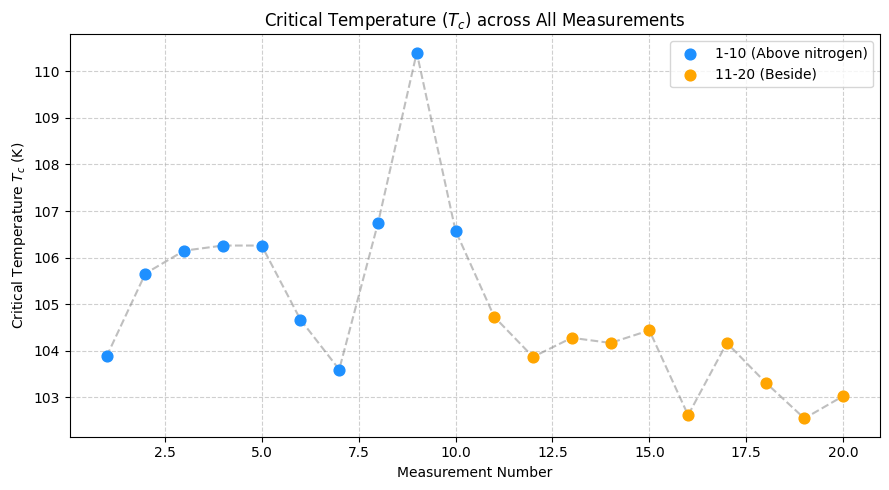

In [29]:
import matplotlib.pyplot as plt
import pandas as pd

# Load the results table
df = pd.read_csv('Tc_results_table.csv')

# Drop rows where Tc fit failed (NaN values)
df_clean = df.dropna(subset=['Tc_fit (K)'])

plt.figure(figsize=(9, 5))

# Separate by group to maintain consistent coloring
group1 = df_clean[df_clean['Group'] == '1-10 (Above nitrogen)']
group2 = df_clean[df_clean['Group'] == '11-20 (Beside)']

plt.scatter(
    group1['Measurement'],
    group1['Tc_fit (K)'],
    color='dodgerblue',
    s=60,
    zorder=3,
    label='1-10 (Above nitrogen)',
)
plt.scatter(
    group2['Measurement'],
    group2['Tc_fit (K)'],
    color='orange',
    s=60,
    zorder=3,
    label='11-20 (Beside)',
)

# Connect points with a light trend line
plt.plot(
    df_clean['Measurement'],
    df_clean['Tc_fit (K)'],
    linestyle='--',
    color='gray',
    alpha=0.5,
    zorder=2,
)

plt.title('Critical Temperature ($T_c$) across All Measurements')
plt.xlabel('Measurement Number')
plt.ylabel('Critical Temperature $T_c$ (K)')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.tight_layout()

plt.show()

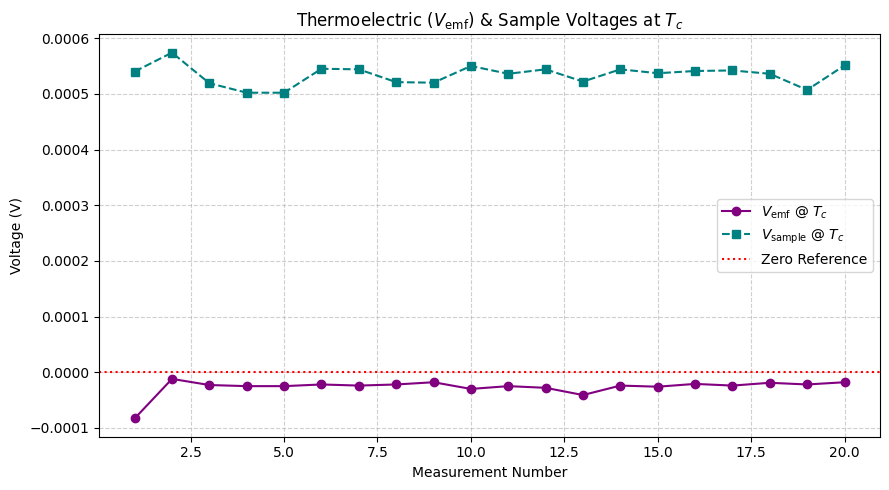

In [ ]:
    import matplotlib.pyplot as plt
    import pandas as pd

    # Load the results table
    df = pd.read_csv('Tc_results_table.csv')

    plt.figure(figsize=(9, 5))

    # Plot V_emf and V_sample at Tc
    plt.plot(
        df['Measurement'],
        df['V emf @ Tc (V)'],
        'o-',
        color='purple',
        label='$V_{\\text{emf}}$ @ $T_c$',
        markersize=6,
    )
    plt.plot(
        df['Measurement'],
        df['V sample @ Tc (V)'],
        's--',
        color='teal',
        label='$V_{\\text{sample}}$ @ $T_c$',
        markersize=6,
    )

    # Reference line at 0 V
    plt.axhline(
        0, color='red', linestyle=':', linewidth=1.5, label='Zero Reference'
    )

    plt.title('Thermoelectric ($V_{\\text{emf}}$) & Sample Voltages at $T_c$')
    plt.xlabel('Measurement Number')
    plt.ylabel('Voltage (V)')
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.legend(loc='best')
    plt.tight_layout()

    plt.show()

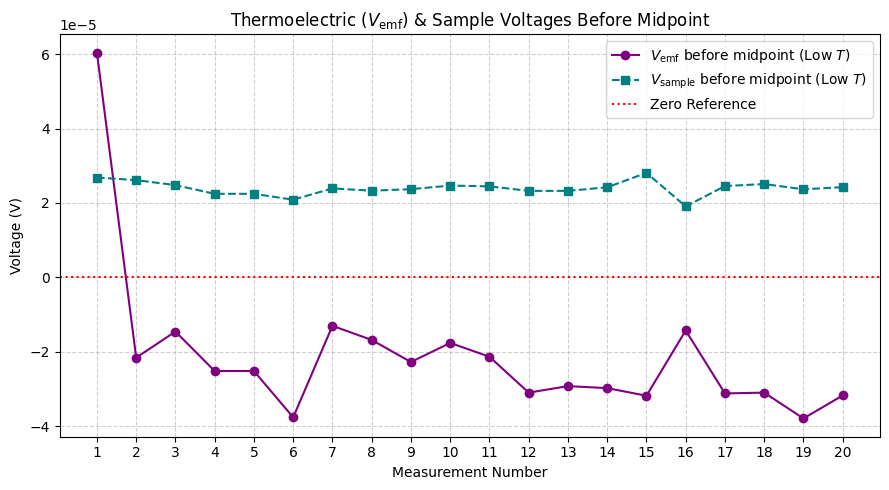

In [38]:
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

measurements = []
v_sample_min = []
v_emf_min = []

# Calibration constants
R_LN2, T_LN2 = 197.6, 77.0
R_room, T_room = 1080.0, 293.15
a = (T_room - T_LN2) / (R_room - R_LN2)
b = T_LN2 - a * R_LN2

# Quickly read the raw files to get the voltages before the midpoint (lowest T)
for i in range(1, 21):
    dmm_file = f'DMMdata_pt1000_{i}.csv'
    smu_file = f'SMUdata_pt1000_{i}.csv'

    if not os.path.exists(dmm_file) or not os.path.exists(smu_file):
        continue

    # Load DMM
    dmm = pd.read_csv(dmm_file, skiprows=5, header=None, names=['R_pt1000'])
    T = a * dmm['R_pt1000'].values + b

    # Load SMU
    with open(smu_file, 'r') as f:
        data_start = next(j + 1 for j, line in enumerate(f.readlines()) if line.strip() == '')
    smu = pd.read_csv(smu_file, skiprows=data_start, header=None, sep='\t')
    
    V1, V2 = smu[0], smu[1]
    V_sample = (V1 - V2) / 2.0
    V_emf = (V1 + V2) / 2.0

    # Filter valid temperatures and find the minimum T (superconducting state)
    valid = (T > 80) & (T < 125)
    if np.any(valid):
        idx_min = np.argmin(T[valid])
        measurements.append(i)
        v_sample_min.append(V_sample.values[valid][idx_min])
        v_emf_min.append(V_emf.values[valid][idx_min])

# --- PLOT ---
plt.figure(figsize=(9, 5))

plt.plot(
    measurements,
    v_emf_min,
    'o-',
    color='purple',
    label='$V_{\\text{emf}}$ before midpoint (Low $T$)',
    markersize=6,
)
plt.plot(
    measurements,
    v_sample_min,
    's--',
    color='teal',
    label='$V_{\\text{sample}}$ before midpoint (Low $T$)',
    markersize=6,
)

# Reference line at 0 V
plt.axhline(
    0, color='red', linestyle=':', linewidth=1.5, label='Zero Reference'
)

plt.title('Thermoelectric ($V_{\\text{emf}}$) & Sample Voltages Before Midpoint')
plt.xlabel('Measurement Number')
plt.ylabel('Voltage (V)')
plt.xticks(measurements) 
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(loc='best')
plt.tight_layout()

plt.show()

In [26]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import savgol_filter, medfilt
import os

def process_all_measurements_onset(total_measurements=20):
    results = []
    
    # Kalibratieconstanten Pt1000 (197.6 Ohm = 77 K, 1080 Ohm = 293.15 K)
    R_LN2, T_LN2 = 197.6, 77.0
    R_room, T_room = 1080.0, 293.15
    a = (T_room - T_LN2) / (R_room - R_LN2)
    b = T_LN2 - a * R_LN2

    for i in range(1, total_measurements + 1):
        dmm_file = f'DMMdata_pt1000_{i}.csv'
        smu_file = f'SMUdata_pt1000_{i}.csv'
        
        # Controleer of de bestanden bestaan
        if not os.path.exists(dmm_file) or not os.path.exists(smu_file):
            print(f"Meting {i}: Bestanden niet gevonden, wordt overgeslagen.")
            continue
            
        # 1. Inladen DMM data
        dmm = pd.read_csv(dmm_file, skiprows=5, header=None, names=['R_pt1000'])
        dmm['T_K'] = a * dmm['R_pt1000'] + b

        # Inladen SMU data (zoek eerste lege regel)
        with open(smu_file, 'r') as f:
            lines = f.readlines()
            data_start = next(j + 1 for j, line in enumerate(lines) if line.strip() == "")
        smu = pd.read_csv(smu_file, skiprows=data_start, header=None, sep='\t')

        # 2. Vemf compensatie: R = (V1 - V2) / (I1 - I2)
        V1, V2 = smu[0], smu[1]
        R_sample = (V1 - V2) / 0.2  # 0.1A - (-0.1A)
        V_sample = (V1 - V2) / 2.0
        V_emf = (V1 + V2) / 2.0
        
        T = dmm['T_K'].values
        R = R_sample.values
        V_samp = V_sample.values
        V_e = V_emf.values

        # Sorteer chronologisch op stijgende temperatuur
        sort_idx = np.argsort(T)
        T, R, V_samp, V_e = T[sort_idx], R[sort_idx], V_samp[sort_idx], V_e[sort_idx]

        # 3. Piek- en ruisfiltering
        valid_range = (R > -0.005) & (R < 0.02) & (T > 80) & (T < 125)
        T, R, V_samp, V_e = T[valid_range], R[valid_range], V_samp[valid_range], V_e[valid_range]

        if len(T) < 10:
            print(f"Meting {i}: Onvoldoende bruikbare datapunten.")
            continue

        R_med = medfilt(R, kernel_size=5)
        valid_med = np.abs(R - R_med) < 0.002
        T, R, V_samp, V_e = T[valid_med], R[valid_med], V_samp[valid_med], V_e[valid_med]

        T_uniq, indices = np.unique(T, return_index=True)
        R_uniq = R[indices]
        V_samp_uniq = V_samp[indices]
        V_e_uniq = V_e[indices]

        # 4. Savitzky-Golay smoothing
        window = min(41, len(R_uniq) - 1 if (len(R_uniq) - 1) % 2 != 0 else len(R_uniq) - 2)
        R_sg = savgol_filter(R_uniq, window_length=window, polyorder=3) if window > 3 else R_uniq

        # 5. Onset Tc Berekening
        R_min = np.min(R_sg[T_uniq < 95])
        mask_norm = (T_uniq > 115) & (T_uniq < 122)
        
        # A. 90% Drempelwaarde
        R_normaal = np.mean(R_sg[mask_norm])
        R_target_90 = R_min + 0.90 * (R_normaal - R_min)
        idx_90 = np.argmin(np.abs(R_sg - R_target_90))
        Tc_onset_90 = T_uniq[idx_90]
        R_onset_90 = R_sg[idx_90]

        # B. Raaklijnmethode
        fit_norm = np.polyfit(T_uniq[mask_norm], R_sg[mask_norm], 1)
        
        mask_trans = (T_uniq > 100) & (T_uniq < 108)
        dR_dT = np.gradient(R_sg, T_uniq)
        sub_indices = np.where(mask_trans)[0]
        idx_max = sub_indices[np.argmax(dR_dT[mask_trans])]
        
        T_mid = T_uniq[idx_max]
        m_tan = dR_dT[idx_max]
        b_tan = R_sg[idx_max] - m_tan * T_mid
        
        Tc_onset_tan = (b_tan - fit_norm[1]) / (fit_norm[0] - m_tan)
        R_onset_tan = fit_norm[0] * Tc_onset_tan + fit_norm[1]

        # Waarden verzamelen bij Onset (90%)
        idx_tc = np.argmin(np.abs(T_uniq - Tc_onset_90))
        groep = "1-10 (Boven stikstof)" if i <= 10 else "11-20 (Ernaast)"
        
        results.append({
            'Meting': i,
            'Groep': groep,
            'Tc Onset 90% (K)': round(Tc_onset_90, 2),
            'Tc Onset Raaklijn (K)': round(Tc_onset_tan, 2),
            'R sample @ Onset (Ohm)': round(R_uniq[idx_tc], 6),
            'V sample @ Onset (V)': round(V_samp_uniq[idx_tc], 6),
            'V emf @ Onset (V)': round(V_e_uniq[idx_tc], 6)
        })

        # 6. Losse Grafiek per meting
        plt.figure(figsize=(9, 5.5))
        color_dot = 'dodgerblue' if i <= 10 else 'orange'
        color_line = 'darkblue' if i <= 10 else 'darkred'

        plt.plot(T_uniq, R_uniq, 'o', color=color_dot, alpha=0.3, markersize=4, label='Gefilterde Data')
        plt.plot(T_uniq, R_sg, '-', color=color_line, linewidth=2, label='Savitzky-Golay Fit')

        plt.plot(Tc_onset_90, R_onset_90, 'ro', markersize=8, label=f'Onset 90% ({Tc_onset_90:.2f} K)')
        plt.plot(Tc_onset_tan, R_onset_tan, 'go', markersize=8, label=f'Onset Raaklijn ({Tc_onset_tan:.2f} K)')

        T_line = np.linspace(98, 122, 100)
        plt.plot(T_line, fit_norm[0]*T_line + fit_norm[1], 'k--', alpha=0.5, label='Normaaltoestand fit')
        plt.plot(T_line, m_tan*T_line + b_tan, 'm--', alpha=0.5, label='Steilste raaklijn')

        plt.title(f'R-T Curve en Onset $T_c$ Bepaling (Meting {i} - {groep})', fontsize=12)
        plt.xlabel('Temperatuur (K)', fontsize=11)
        plt.ylabel('Gecompenseerde Weerstand (Ohm)', fontsize=11)
        plt.xlim(92, 122)
        plt.ylim(-0.001, np.max(R_sg)*1.15)
        plt.grid(True, linestyle='--', alpha=0.6)
        plt.legend(loc='upper left', fontsize=10)
        plt.tight_layout()
        
        plt.savefig(f'Meting_{i}_onset_plot.png', dpi=150)
        plt.close() # Geheugen opschonen per figuur

    # Sla alle resultaten op in een CSV
    df = pd.DataFrame(results)
    df.to_csv('Onset_Tc_results_table.csv', index=False)
    print("\nAlle metingen verwerkt! Tabel opgeslagen als 'Onset_Tc_results_table.csv'.")
    print(df.to_string(index=False))

# Voer uit voor alle 20 metingen:
process_all_measurements_onset(20)


Alle metingen verwerkt! Tabel opgeslagen als 'Onset_Tc_results_table.csv'.
 Meting                 Groep  Tc Onset 90% (K)  Tc Onset Raaklijn (K)  R sample @ Onset (Ohm)  V sample @ Onset (V)  V emf @ Onset (V)
      1 1-10 (Boven stikstof)            110.34                 104.63                0.008790              0.000879          -0.000036
      2 1-10 (Boven stikstof)            114.02                 107.89                0.009400              0.000940          -0.000039
      3 1-10 (Boven stikstof)            111.64                 108.25                0.008626              0.000863          -0.000018
      4 1-10 (Boven stikstof)            111.21                 108.60                0.008525              0.000852          -0.000027
      5 1-10 (Boven stikstof)            111.21                 108.60                0.008525              0.000852          -0.000027
      6 1-10 (Boven stikstof)            110.56                 107.07                0.008865              